# Module project: build a clothes classifier you can trust

This notebook builds the whole project, file by file, exactly as the lesson does. Run it from top to bottom in Google Colab or Jupyter: each `%%writefile` cell writes one file of the project, and each `!python` cell runs it. Then try the ideas under **Make it yours**.

Better still: type the files yourself in your own editor, and use this notebook to check your work.

## Attachments and data

- **Notebook**: `project-6-clothes-classifier.ipynb`, attached to this lesson. It builds and runs the whole project; on the course's web page it opens in Google Colab.
- **Finished code**: the `projects/clothes-classifier` folder in the course files, to check your work.
- **Data**: Fashion-MNIST (Zalando Research). Source: [https://github.com/zalandoresearch/fashion-mnist/tree/master/data/fashion](https://github.com/zalandoresearch/fashion-mnist/tree/master/data/fashion) · about: [https://github.com/zalandoresearch/fashion-mnist](https://github.com/zalandoresearch/fashion-mnist) · licence: MIT. `data.py` downloads it the first time you run it and keeps it in `data/`: `t10k-images-idx3-ubyte.gz`, `t10k-labels-idx1-ubyte.gz`, `train-images-idx3-ubyte.gz`, `train-labels-idx1-ubyte.gz`, 29.4 MB.
- **All datasets in one zip**: [bishop-datasets.zip](https://github.com/mahmoudyosrimahmoud13/inpace-library/releases/download/bishop-datasets-v1/bishop-datasets.zip). Unzip it and copy the files of `fashion-mnist` into your project's `data/` folder; `data.py` then skips the download. Useful offline, or if a source moves.

In [ ]:
%pip install -q torch matplotlib

Chapter 5 gave you two ways to build a classifier: model each class and use Bayes' theorem (**generative**), or model
`p(class | input)` directly (**discriminative**). It also asked a question most tutorials skip: what should the
classifier do when it isn't sure?

In this project you build both kinds for a real 10-class image problem, Fashion-MNIST, compare them, check whether their
probabilities can be trusted, and add a reject option. It's your first PyTorch training loop on images. The notebook
attached above builds and runs everything; the reference code is under `projects/clothes-classifier` in the course files.

## What you'll build

```mermaid
flowchart LR
    A[Fashion-MNIST<br/>70,000 photos, 10 classes] --> B[data.py<br/>download + split]
    B --> C[models.py<br/>Gaussian classifier<br/>softmax regression]
    C --> D[train.py<br/>validation comparison]
    D --> E[evaluate.py<br/>test once: confusions,<br/>calibration, reject option]
    D --> F[show_weights.py<br/>look inside]
```

Fashion-MNIST was made by Zalando Research as a harder replacement for handwritten digits: 28 × 28 grey photos of
T-shirts, trousers, bags, shoes and so on. Each image is 784 numbers, one per pixel.

## Set up the project

```bash
mkdir clothes-classifier && cd clothes-classifier
python -m venv .venv && source .venv/bin/activate
pip install torch matplotlib
git init
```

```text
clothes-classifier/
    .gitignore
    README.md
    data.py
    evaluate.py
    models.py
    requirements.txt
    show_weights.py
    softmax.pt
    train.py
```

In [2]:
%%writefile requirements.txt
torch
matplotlib

Writing requirements.txt


In [3]:
%%writefile .gitignore
data/
outputs/
__pycache__/
*.pt
.venv/

Writing .gitignore


## Step 1: the data

The files come in a simple binary format (a small header, then raw bytes), so we read them ourselves: a good thing to
know how to do. We keep 10,000 of the 60,000 training images for validation; the official 10,000 test images are kept
for the very end.

In [4]:
%%writefile data.py
"""Fashion-MNIST: 70,000 grey 28x28 photos of clothes in 10 classes (Zalando Research)."""
from pathlib import Path
from urllib.request import urlopen
import gzip
import torch

URL = "https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/"
CLASSES = ["T-shirt", "trouser", "pullover", "dress", "coat", "sandal", "shirt", "sneaker", "bag", "ankle boot"]


def _read(name, offset):
    path = Path("data") / name
    if not path.exists():
        path.parent.mkdir(exist_ok=True)
        path.write_bytes(urlopen(URL + name).read())
    raw = gzip.decompress(path.read_bytes())
    return torch.frombuffer(bytearray(raw[offset:]), dtype=torch.uint8)


def load(split):
    """split: 'train' (60,000 images) or 't10k' (10,000). Returns images as (N, 784) floats in [0, 1] and labels."""
    x = _read(f"{split}-images-idx3-ubyte.gz", 16).reshape(-1, 784).float() / 255
    t = _read(f"{split}-labels-idx1-ubyte.gz", 8).long()
    return x, t


def load_splits():
    x, t = load("train")
    g = torch.Generator().manual_seed(0)
    order = torch.randperm(len(x), generator=g)
    val, train = order[:10000], order[10000:]
    return (x[train], t[train]), (x[val], t[val]), load("t10k")


if __name__ == "__main__":
    (xtr, ttr), (xva, tva), (xte, tte) = load_splits()
    print(f"train {len(xtr)}, validation {len(xva)}, test {len(xte)} images of {xtr.shape[1]} pixels")
    print("images per class in training:", torch.bincount(ttr).tolist())

Writing data.py


In [5]:
!python data.py

train 50000, validation 10000, test 10000 images of 784 pixels
images per class in training: [5009, 5022, 5012, 5001, 5052, 5001, 4945, 4984, 4974, 5000]


## Step 2: two classifiers

**The generative classifier** (section 5.3) fits one Gaussian per class, all sharing one covariance matrix, and applies
Bayes' theorem. Section 5.3.1 shows that the shared covariance makes the quadratic terms cancel, so each class score is
**linear** in the pixels, and the code computes it directly from the means and the inverse covariance. There's no
training loop: everything is a mean, a covariance and an inverse. One practical detail: pixels at the border are almost
always 0, which makes the covariance impossible to invert, so we add a small `eps` to its diagonal.

**Softmax regression** (section 5.4.4) has exactly the same form, a linear score per class followed by softmax, but
learns the weights directly by minimizing the cross-entropy. In PyTorch it's a single `nn.Linear(784, 10)`;
`F.cross_entropy` applies the softmax itself.

In [6]:
%%writefile models.py
"""Two ways to build a 10-class classifier (Bishop, chapter 5)."""
import torch
from torch import nn


class GaussianClassifier:
    """Generative (section 5.3): one Gaussian per class with a SHARED covariance, then Bayes' theorem.
    Fitted in closed form, no training loop. The decision boundaries come out linear."""
    def fit(self, X, t, eps=0.05):
        K = int(t.max()) + 1
        self.means = torch.stack([X[t == k].mean(0) for k in range(K)])
        centred = X - self.means[t]
        cov = centred.T @ centred / len(X) + eps * torch.eye(X.shape[1])   # eps: many border pixels are always 0
        self.precision = torch.linalg.inv(cov)
        self.log_prior = torch.log(torch.bincount(t, minlength=K).float() / len(t))
        return self

    def logits(self, X):
        # a_k(x) = w_k^T x + w_k0  with  w_k = S^-1 mu_k,  w_k0 = -mu_k^T S^-1 mu_k / 2 + ln p(C_k)
        W = self.means @ self.precision
        b = -0.5 * (W * self.means).sum(1) + self.log_prior
        return X @ W.T + b


class SoftmaxRegression(nn.Module):
    """Discriminative (section 5.4.4): model p(C_k | x) = softmax(W x + b) directly, train by cross-entropy."""
    def __init__(self, D=784, K=10):
        super().__init__()
        self.linear = nn.Linear(D, K)

    def forward(self, X):
        return self.linear(X)

Writing models.py


## Step 3: train and compare

In [7]:
%%writefile train.py
"""Fit both classifiers and compare them on the validation set."""
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from data import load_splits
from models import GaussianClassifier, SoftmaxRegression

torch.manual_seed(0)
(xtr, ttr), (xva, tva), _ = load_splits()


def evaluate(logits, t):
    return (logits.argmax(1) == t).float().mean().item(), F.cross_entropy(logits, t).item()


gen = GaussianClassifier().fit(xtr, ttr)
acc, ce = evaluate(gen.logits(xva), tva)
print(f"generative Gaussian classifier: validation accuracy {acc:.3f}, cross-entropy {ce:.3f}")

model = SoftmaxRegression()
opt = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-5)
loader = DataLoader(TensorDataset(xtr, ttr), batch_size=128, shuffle=True)
for epoch in range(1, 16):
    for x, t in loader:
        loss = F.cross_entropy(model(x), t)
        opt.zero_grad(); loss.backward(); opt.step()
    if epoch in (1, 5, 10, 15):
        with torch.no_grad():
            acc, ce = evaluate(model(xva), tva)
        print(f"softmax regression, epoch {epoch:2d}: validation accuracy {acc:.3f}, cross-entropy {ce:.3f}")
torch.save(model.state_dict(), "softmax.pt")

Writing train.py


In [8]:
!python train.py

generative Gaussian classifier: validation accuracy 0.803, cross-entropy 0.926


softmax regression, epoch  1: validation accuracy 0.798, cross-entropy 0.586


softmax regression, epoch  5: validation accuracy 0.839, cross-entropy 0.470


softmax regression, epoch 10: validation accuracy 0.850, cross-entropy 0.442


softmax regression, epoch 15: validation accuracy 0.853, cross-entropy 0.434


Same form of model, very different results. Softmax regression wins on accuracy (0.853 against 0.803), and by far on
cross-entropy (0.43 against 0.93). Section 5.4's argument in practice: the generative model spends its effort describing
each class as a Gaussian, which photos of clothes are not, while softmax regression spends all its parameters on the only
thing we need, the boundaries between classes.

## Step 4: the final evaluation

Now the test set, once. Three questions:

1. **What's hard?** A confusion matrix shows which classes are mistaken for which.
2. **Can the probabilities be trusted?** A model is **calibrated** if, among all the images it's 80% sure about, about
   80% are right. The expected calibration error averages the gap over confidence levels.
3. **Can we do better by refusing?** Section 5.2.3's **reject option**: when the largest posterior probability is
   below a threshold θ, don't decide, and pass the image to a human.

In [9]:
%%writefile evaluate.py
"""Final evaluation on the 10,000 test images (used once): accuracy, what gets confused, whether the
probabilities can be trusted (calibration), and a reject option (Bishop, section 5.2.3)."""
from pathlib import Path
import torch
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from data import load_splits, CLASSES
from models import GaussianClassifier, SoftmaxRegression

(xtr, ttr), _, (xte, tte) = load_splits()
model = SoftmaxRegression()
model.load_state_dict(torch.load("softmax.pt"))
with torch.no_grad():
    probs = {"softmax regression": torch.softmax(model(xte), 1),
             "Gaussian classifier": torch.softmax(GaussianClassifier().fit(xtr, ttr).logits(xte), 1)}

p = probs["softmax regression"]
guess = p.argmax(1)
print(f"TEST accuracy, softmax regression: {(guess == tte).float().mean():.3f}\n")

confusion = torch.zeros(10, 10, dtype=torch.long)
confusion.index_put_((tte, guess), torch.ones_like(tte), accumulate=True)
print("per-class accuracy:")
for k in confusion.diag().float().div(confusion.sum(1)).argsort():
    worst = confusion[k].clone(); worst[k] = 0
    print(f"  {CLASSES[k]:10s} {confusion[k, k] / confusion[k].sum():.2f}   most often mistaken for {CLASSES[worst.argmax()]}")


def calibration(p, t, bins=10):
    """Group predictions by confidence; in a calibrated model, 80%-confident predictions are right 80% of the time."""
    conf, guess = p.max(1)
    edges = torch.linspace(0, 1, bins + 1)
    rows, ece = [], 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.sum() > 0:
            acc, c = (guess[m] == t[m]).float().mean().item(), conf[m].mean().item()
            rows.append((c, acc))
            ece += m.float().mean().item() * abs(acc - c)          # expected calibration error
    return rows, ece


Path("outputs").mkdir(exist_ok=True)
plt.figure(figsize=(4.5, 4.5))
plt.plot([0, 1], [0, 1], "k:", label="perfectly calibrated")
print()
for name, q in probs.items():
    rows, ece = calibration(q, tte)
    print(f"{name:20s} expected calibration error {ece:.3f}")
    plt.plot(*zip(*rows), "o-", label=name)
plt.xlabel("confidence"); plt.ylabel("accuracy"); plt.legend(); plt.title("Calibration on the test set")
plt.tight_layout(); plt.savefig("outputs/calibration.png", dpi=120)

print("\nreject option: refuse the least confident images, and pass them to a human")
conf = p.max(1).values
for share in [0.0, 0.1, 0.2, 0.3]:
    theta = torch.quantile(conf, share)
    keep = conf >= theta
    print(f"  refuse {share:.0%} (confidence below {theta:.2f}): accuracy on the rest {(guess[keep] == tte[keep]).float().mean():.3f}")
print("\nsaved outputs/calibration.png")

Writing evaluate.py


In [10]:
!python evaluate.py

TEST accuracy, softmax regression: 0.845

per-class accuracy:
  shirt      0.58   most often mistaken for T-shirt
  coat       0.74   most often mistaken for pullover
  pullover   0.74   most often mistaken for coat
  T-shirt    0.81   most often mistaken for shirt
  dress      0.86   most often mistaken for shirt
  sandal     0.92   most often mistaken for sneaker
  sneaker    0.93   most often mistaken for ankle boot
  ankle boot 0.95   most often mistaken for sneaker
  bag        0.95   most often mistaken for shirt
  trouser    0.96   most often mistaken for dress



softmax regression   expected calibration error 0.009
Gaussian classifier  expected calibration error 0.123



reject option: refuse the least confident images, and pass them to a human
  refuse 0% (confidence below 0.22): accuracy on the rest 0.845
  refuse 10% (confidence below 0.53): accuracy on the rest 0.887
  refuse 20% (confidence below 0.65): accuracy on the rest 0.926
  refuse 30% (confidence below 0.77): accuracy on the rest 0.950

saved outputs/calibration.png


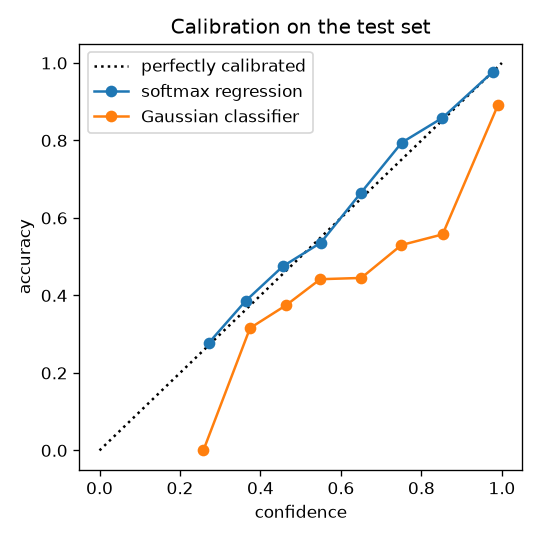

In [11]:
from IPython.display import Image
Image('outputs/calibration.png')

What the numbers say:

- Test accuracy is 0.845, close to validation: no surprise, which is what you want.
- **Shirts** are the weak spot (0.58), mixed up with T-shirts, pullovers and coats. In a 28 × 28 photo they really do look
  alike, and a linear model can only weigh pixels, not notice "a collar" or "buttons". That's the job of the deep
  networks in the next parts.
- Softmax regression is very well calibrated (error 0.009): training by cross-entropy rewards honest probabilities.
  The Gaussian classifier is badly calibrated (0.123), because its wrong Gaussian assumption makes it over-confident.
- Because the probabilities are honest, the reject option works: refusing 10% of images lifts accuracy to 0.887,
  refusing 30% to 0.950. Whether that's worth it is a business decision, and now you can give the numbers for it.

## Step 5: look inside

With one weight per pixel per class, you can draw what the model learned:

In [12]:
%%writefile show_weights.py
"""Each class has 784 weights, one per pixel: draw them as images to see what the model looks for."""
import torch
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from data import CLASSES
from models import SoftmaxRegression

model = SoftmaxRegression()
model.load_state_dict(torch.load("softmax.pt"))
W = model.linear.weight.detach()
fig, axes = plt.subplots(2, 5, figsize=(10, 4.4))
for k, ax in enumerate(axes.flat):
    lim = W[k].abs().max()
    ax.imshow(W[k].reshape(28, 28), cmap="RdBu_r", vmin=-lim, vmax=lim)
    ax.set_title(CLASSES[k]); ax.axis("off")
fig.suptitle("Weights per class: red pixels raise the score, blue pixels lower it")
fig.tight_layout(); fig.savefig("outputs/weights.png", dpi=110)
print("saved outputs/weights.png")

Writing show_weights.py


In [13]:
!python show_weights.py

saved outputs/weights.png


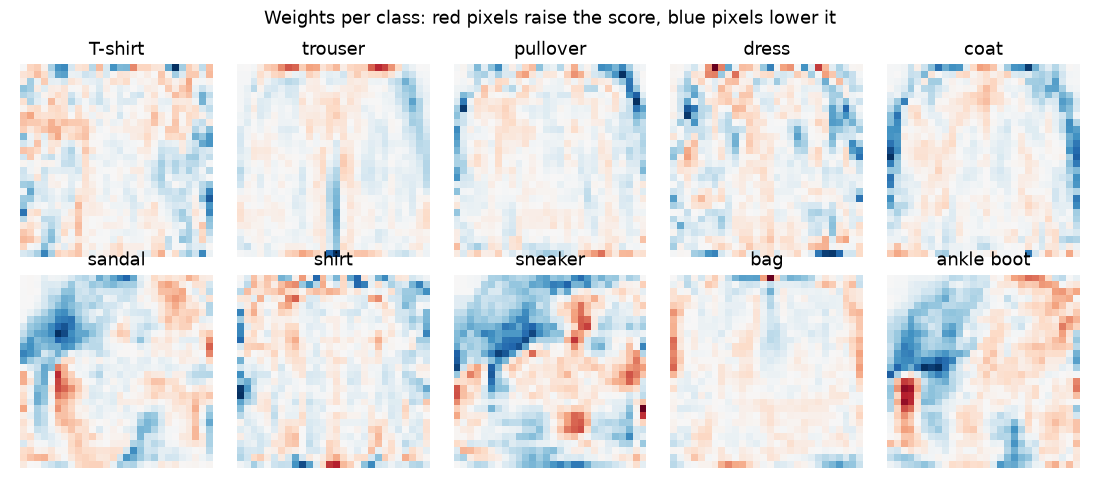

In [14]:
from IPython.display import Image
Image('outputs/weights.png')

Look at **trouser**: a blue stripe down the middle. Light pixels between the legs are evidence **against** trousers. The
shoe classes look at the ankle area to tell sandals, sneakers and boots apart. Each class's weights form a rough
template, and the score is how well the image matches it.

## Step 6: write the README and publish

In [15]:
%%writefile README.md
# Clothes classifier

A 10-class image classifier for Fashion-MNIST (70,000 photos of clothes) built in PyTorch with two models from
chapter 5: a generative Gaussian classifier and softmax regression. Includes a calibration check and a reject option.

![weights](outputs/weights.png)

## Results (10,000 test images, used once)

| model | validation accuracy | test accuracy | calibration error |
|---|---|---|---|
| Gaussian classifier (shared covariance) | 0.803 | | 0.123 |
| softmax regression (15 epochs, Adam) | 0.853 | **0.845** | **0.009** |

Reject option (softmax regression): refusing the 10% least confident images raises accuracy to 0.887; refusing 30%
raises it to 0.950. Hardest class: shirt (0.58), most often confused with T-shirt.

![calibration](outputs/calibration.png)

## Run it

```bash
pip install -r requirements.txt
python train.py          # fit both models, validation results
python evaluate.py       # test set: accuracy, confusions, calibration, reject option
python show_weights.py   # what each class's weights look for
```

## What I learned

- Discriminative models usually beat generative ones when the generative assumptions (Gaussian classes) are wrong.
- Accuracy isn't the whole story: calibrated probabilities make a reject option possible.
- A linear model can't tell a shirt from a T-shirt; that needs the non-linear features of deep networks.

Based on chapter 5 of *Deep Learning: Foundations and Concepts* (Bishop & Bishop, 2024).

Writing README.md


```bash
git add .
git commit -m "Fashion-MNIST classifier: generative vs discriminative, calibration, reject option"
git branch -M main
git remote add origin git@github.com:YOUR-USERNAME/clothes-classifier.git
git push -u origin main
```

## Make it yours

- **Tune `eps`.** The Gaussian classifier's `eps` was a guess. Choose it on the validation set. How close can it get to
  softmax regression?
- **A loss matrix.** Suppose confusing a coat with a shirt costs nothing, but calling a bag a shoe costs 10. Use the
  minimum-expected-loss rule of section 5.2.2 instead of the largest probability.
- **Show the mistakes.** Plot the 16 test images the model got wrong with the highest confidence. Are some labels
  actually wrong?
- **One hidden layer.** Replace `nn.Linear(784, 10)` with `nn.Sequential(nn.Linear(784, 256), nn.ReLU(), nn.Linear(256, 10))`.
  How much do the shirts improve? (Part 2 of this course explains why it works.)

## On your CV

> **Clothes classifier** (PyTorch): generative Gaussian vs. softmax regression on Fashion-MNIST; 84.5% test accuracy with
> calibration error 0.009, and a reject option reaching 95% accuracy on the 70% most confident images.
> github.com/YOUR-USERNAME/clothes-classifier

## Check yourself

- [ ] You can explain why the shared-covariance Gaussian classifier has linear decision boundaries.
- [ ] You can explain what calibration means, using one row of your own results.
- [ ] The test set was used once, after all choices were made on validation.